# Datalab 2025-2026

Groepsnummer:
Groepsleden:

In [22]:
# Import libraries

import pandas as pd
import numpy as np|
import cbsodata

# Gebruik een CBS-tabelcode (bijv. '83765ned' voor bevolkingsdata)
tabelcode = '85618NED'

# Haal de data direct op
data = cbsodata.get_data(tabelcode)
# Laad de data in een DataFrame
df = pd.DataFrame(data)

# Toon de eerste 5 rijen

buurten = df[df['SoortRegio_2'] == 'Buurt     ']
# door te filteren op de buurten, kunnen we de data beter analyseren en visualiseren, omdat buurten vaak specifieke kenmerken hebben die relevant zijn voor energiebedrijven om de energiebehoefte en -consumptie in kaart te brengen. Door te focussen op buurten kunnen we gerichte inzichten verkrijgen die kunnen helpen bij het optimaliseren van energievoorziening en -beleid.
df.shape
## Kaan is net als Toji

pd.set_option('display.max_rows', 200) # Hier kan je het aantal regels dat wordt weergegeven in je dataframe aanpassen
pd.set_option('display.max_columns', 200) # Hier kan je het aantal kolommen dat wordt weergegeven in je dataframe aanpassen

## Sprint 3

In [3]:
# Dataset importeren
buurten = df[df['SoortRegio_2'].str.strip() == 'Buurt']

NameError: name 'df' is not defined

In [ ]:
# Dataframe buurten maken


## Sprint 3 – Data opschonen

### 1. Dataset inspecteren


In [2]:
# Aantal rijen en kolommen dataframe

#### Omschrijving van de kolommen



| kolomnaam | omschrijving | type | eenheden | missende waarden |
| ---       |---           | ---  | ---      | ---              |
| ...       | ...  | ...      | ...              |...

#### Extra omschrijving numerieke kolommen

| kolomnaam | maximum | minimum | gemiddelde | mediaan |
|---        | ---     |---      |---         |---      |
|...        | ...     |...      |...         |...      |



#### Relevante kolommen
...

In [ ]:
# Verwijderen van irrelevante kolommen

#### Onderbouwing te veel missende waardes
...

In [ ]:
# Verwijderen van kolommen met te veel missende waardes

#### Basisstatistieken



In [ ]:
# Basisstatistieken:

##kyra
# Totalen per gemeente 
# geschikte kolommen voor totalen selecteren
# totalen per gemeente berekenen .groupby()
# aantal inwoners per gemeeente  

import pandas as pd
#meetwaarden data set obs=observations
df_obs= pd.read_csv("Observations.csv", sep=";" )
#gebiedscodes & namen 
df_regios= pd.read_csv("WijkenEnBuurtenCodes.csv", sep=";")
#rijen & kolom namen 
print("Observattions:")
display(df_obs.head(3))

print("regio codes:")
display(df_regios.head(3))

#gegevens koppelen per gemeente 
df_totaal= pd.merge(df_obs, df_regios, how="left", left_on= "WijkenEnBuurten", right_on="Identifier")
display(df_totaal.head(5))

# filteren enkel data gemeente GM  (geschikte kolommen voor totalen selecteren)
df_totaal ["Value"]= pd.to_numeric(df_totaal["Value"], errors="coerce")
# aantal inwoners per gemeeente  
df_gemeente_inwoners= df_totaal[(df_totaal["DimensionGroupId"]== "GM") & (df_totaal["Measure"]=="T001036" )]
#groepeer per gemeente  (totalen per gemeente berekenen .groupby())
totalen_per_gemeente= (df_gemeente_inwoners.groupby("Title")["Value"].sum().reset_index())
display(totalen_per_gemeente.head())

Observattions:


,Id,Measure,WijkenEnBuurten,Value,StringValue,ValueAttribute
0,0,GM000C,NL00,NaN,Nederland,NaN
1,1,R00003,NL00,NaN,Land,NaN
2,2,R00004,NL00,NaN,NL00,NaN


regio codes:


,Identifier,DimensionGroupId,DimensionId,Index,Title,Description,DetailRegionCode
0,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
1,GM1680,GM,WijkenEnBuurten,2,Aa en Hunze,Gemeente 'Aa en Hunze' (GM1680),GM1680
2,WK168000,GM1680,WijkenEnBuurten,3,Wijk 00 Annen,Wijk 'Wijk 00 Annen' (WK168000) is een wijk in...,WK168000


,Id,Measure,WijkenEnBuurten,Value,StringValue,ValueAttribute,Identifier,DimensionGroupId,DimensionId,Index,Title,Description,DetailRegionCode
0,0,GM000C,NL00,NaN,Nederland,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
1,1,R00003,NL00,NaN,Land,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
2,2,R00004,NL00,NaN,NL00,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
3,3,T001036,NL00,17811291,NaN,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
4,4,3000,NL00,8850309,NaN,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN


,Title,Value
0,'s-Gravenhage,562839.0
1,'s-Hertogenbosch,158753.0
2,Aa en Hunze,25724.0
3,Aalsmeer,33063.0
4,Aalten,27244.0


In [ ]:
# Basisstatistieken:
# Percentages

### Voorlopige conclusie

## Sprint 4

342


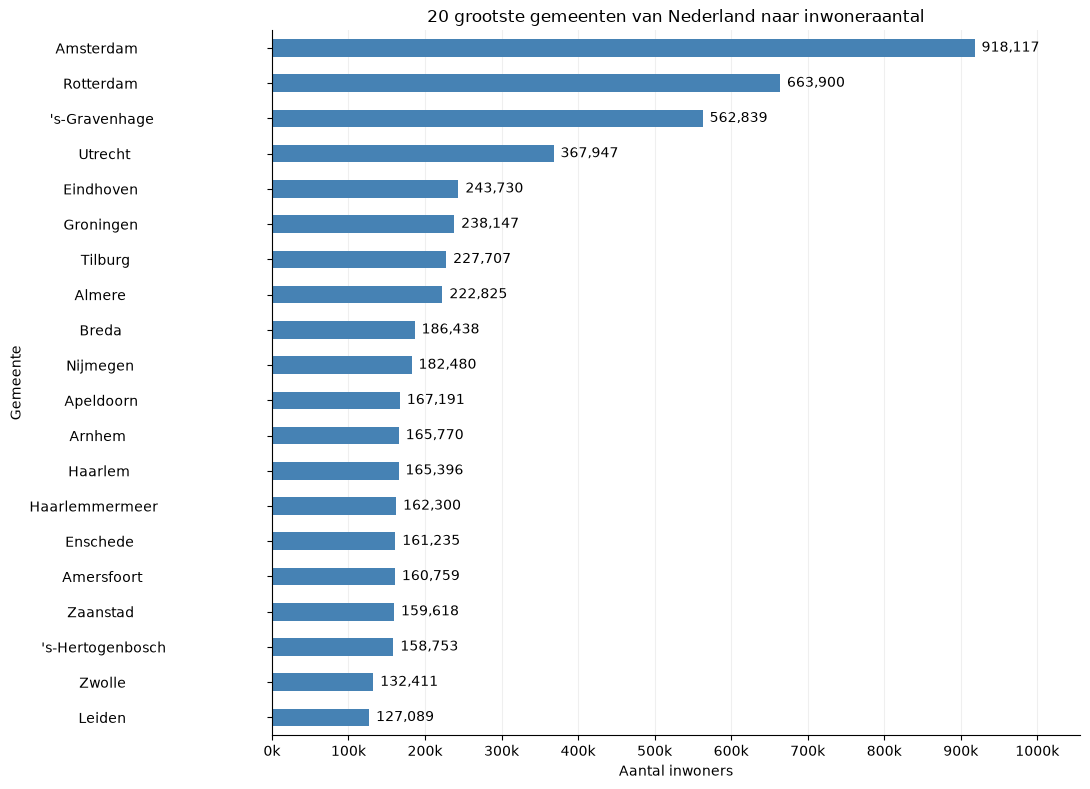

In [ ]:
import matplotlib.pyplot as plt
gemeenten = df[df['SoortRegio_2'].str.strip() == 'Gemeente']

df3 = gemeenten.groupby('Gemeentenaam_1')['AantalInwoners_5'].first()

print(df3.count())

import matplotlib.ticker as ticker

top20 = df3.nlargest(20).sort_values()

ax = top20.plot(
    kind='barh',
    figsize=(11, 8),
    color='steelblue'
)

# Getallen achter de staven
ax.bar_label(ax.containers[0], padding=5, fmt='{:,}')

# X-as in duizendtallen
ax.xaxis.set_major_locator(ticker.MultipleLocator(100000))
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{x/1000:.0f}k')
)

# Bovenste en rechter rand verwijderen
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Rasterlijnen
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)

plt.title('20 grootste gemeenten van Nederland naar inwoneraantal')
plt.xlabel('Aantal inwoners')
plt.ylabel('Gemeente')
plt.xlim(0, top20.max() * 1.15)

plt.tight_layout()
plt.show()

#Uit de grafiek blijkt dat er grote verschillen zijn tussen het aantal inwoners per gemeente. Dit zijn de 20 grootste gemeenten, en Leiden (de onderste) heeft nog steeds bijna 800k minder inwoners dan Amsterdam (de grootste). 
#Dit geeft aan dat de behoefte voor energie enorm kan verschillen per gemeente. Rotterdam bijvoorbeeld zou ook een grotere behoefte hebben dan bijvoorbeeld Zaandam.
#Hiernaast moet er rekening gehouden worden met andere factoren, zoals de type woningen.

In [32]:
df.head()

,ID,WijkenEnBuurten,Gemeentenaam_1,SoortRegio_2,Codering_3,IndelingswijzigingGemeenteWijkBuurt_4,AantalInwoners_5,Mannen_6,Vrouwen_7,k_0Tot15Jaar_8,k_15Tot25Jaar_9,k_25Tot45Jaar_10,k_45Tot65Jaar_11,k_65JaarOfOuder_12,Ongehuwd_13,Gehuwd_14,Gescheiden_15,Verweduwd_16,Nederland_17,EuropaExclusiefNederland_18,BuitenEuropa_19,Nederland_20,EuropaExclusiefNederland_21,BuitenEuropa_22,EuropaExclusiefNederland_23,BuitenEuropa_24,GeboorteTotaal_25,GeboorteRelatief_26,SterfteTotaal_27,SterfteRelatief_28,HuishoudensTotaal_29,Eenpersoonshuishoudens_30,HuishoudensZonderKinderen_31,HuishoudensMetKinderen_32,GemiddeldeHuishoudensgrootte_33,Bevolkingsdichtheid_34,Woningvoorraad_35,GemiddeldeWOZWaardeVanWoningen_36,PercentageEengezinswoning_37,PercentageMeergezinswoning_38,PercentageBewoond_39,PercentageOnbewoond_40,Koopwoningen_41,HuurwoningenTotaal_42,InBezitWoningcorporatie_43,InBezitOverigeVerhuurders_44,EigendomOnbekend_45,BouwjaarVoor2000_46,BouwjaarVanaf2000_47,GemiddeldeElektriciteitsleveringTotaal_48,Appartement_49,Tussenwoning_50,Hoekwoning_51,TweeOnderEenKapWoning_52,VrijstaandeWoning_53,Huurwoning_54,EigenWoning_55,GemiddeldAardgasverbruikTotaal_56,Appartement_57,Tussenwoning_58,Hoekwoning_59,TweeOnderEenKapWoning_60,VrijstaandeWoning_61,Huurwoning_62,EigenWoning_63,PercentageWoningenMetStadsverwarming_64,LeerlingenPo_65,LeerlingenVoInclVavo_66,StudentenMboExclExtranei_67,StudentenHbo_68,StudentenWo_69,BasisonderwijsVmboMbo1_70,HavoVwoMbo24_71,HboWo_72,WerkzameBeroepsbevolking_73,Nettoarbeidsparticipatie_74,PercentageWerknemers_75,WerknemersMetVasteArbeidsrelatie_76,WerknemersMetFlexibeleArbeidsrelatie_77,PercentageZelfstandigen_78,AantalInkomensontvangers_79,GemiddeldInkomenPerInkomensontvanger_80,GemiddeldInkomenPerInwoner_81,k_40PersonenMetLaagsteInkomen_82,k_20PersonenMetHoogsteInkomen_83,GemGestandaardiseerdInkomenVanHuish_84,k_40HuishoudensMetLaagsteInkomen_85,k_20HuishoudensMetHoogsteInkomen_86,HuishoudensMetEenLaagInkomen_87,HuishOnderOfRondSociaalMinimum_88,HuishoudensTot110VanSociaalMinimum_89,HuishoudensTot120VanSociaalMinimum_90,MediaanVermogenVanParticuliereHuish_91,PersonenPerSoortUitkeringBijstand_92,PersonenPerSoortUitkeringAO_93,PersonenPerSoortUitkeringWW_94,PersonenPerSoortUitkeringAOW_95,JongerenMetJeugdzorgInNatura_96,PercentageJongerenMetJeugdzorg_97,WmoClienten_98,WmoClientenRelatief_99,BedrijfsvestigingenTotaal_100,ALandbouwBosbouwEnVisserij_101,BFNijverheidEnEnergie_102,GIHandelEnHoreca_103,HJVervoerInformatieEnCommunicatie_104,KLFinancieleDienstenOnroerendGoed_105,MNZakelijkeDienstverlening_106,OQOverheidOnderwijsEnZorg_107,RUCultuurRecreatieOverigeDiensten_108,PersonenautoSTotaal_109,PersonenautoSBrandstofBenzine_110,PersonenautoSOverigeBrandstof_111,PersonenautoSPerHuishouden_112,PersonenautoSNaarOppervlakte_113,Motorfietsen_114,AfstandTotHuisartsenpraktijk_115,AfstandTotGroteSupermarkt_116,AfstandTotKinderdagverblijf_117,AfstandTotSchool_118,ScholenBinnen3Km_119,OppervlakteTotaal_120,OppervlakteLand_121,OppervlakteWater_122,MeestVoorkomendePostcode_123,Dekkingspercentage_124,MateVanStedelijkheid_125,Omgevingsadressendichtheid_126
0,0,Nederland,Nederland,Land,NL00,.,17811291,8850309,8960982,2727377,2190344,4507646,4784757,3601167,8851656,6709548,1386843,863244,12978154,1617454,3215683,12978154,604926,1451261,1012528,1764422,164487,9.0,169521,10.0,8270244,3266042,2358933,2645269,2.1,529.0,8125229,368.0,64.0,36.0,96.0,4.0,57.0,43.0,28.0,14.0,0.0,81.0,19.0,2500.0,1820.0,2500.0,2660.0,3020.0,3850.0,1910.0,2930.0,820.0,580.0,790.0,920.0,1050.0,1340.0,660.0,950.0,6.8,1466730,956630,468600,460430,343880,3550110.0,5564320.0,4390900.0,9547160,72.0,83.0,55.0,28.0,17.0,14371000,39.7,32.8,40.0,20.0,40.0,40.0,20.0,3.6,6.3,9.5,12.1,134.6,400280.0,768100.0,141950.0,3256970.0,485100.0,10.9,1247750.0,70.0,2358605,80045.0,336575.0,393385.0,179900.0,177825.0,543000.0,390805.0,257070.0,8917105,6992290,1924815,1.1,265.0,690725,1.1,1.0,0.7,0.8,9.9,4154337,3364723,789614,.,NaN,2.0,2055.0
1,1,Aa en Hunze,Aa en Hunze,Gemeente,GM1

MateVanStedelijkheid_125
1.0    4649795
2.0    5288761
3.0    2895280
4.0    3751137
5.0    1226318
Name: AantalInwoners_5, dtype: int64
MateVanStedelijkheid_125
Zeer sterk stedelijk    4649795
Sterk stedelijk         5288761
Matig stedelijk         2895280
Weinig stedelijk        3751137
Niet stedelijk          1226318
Name: AantalInwoners_5, dtype: int64


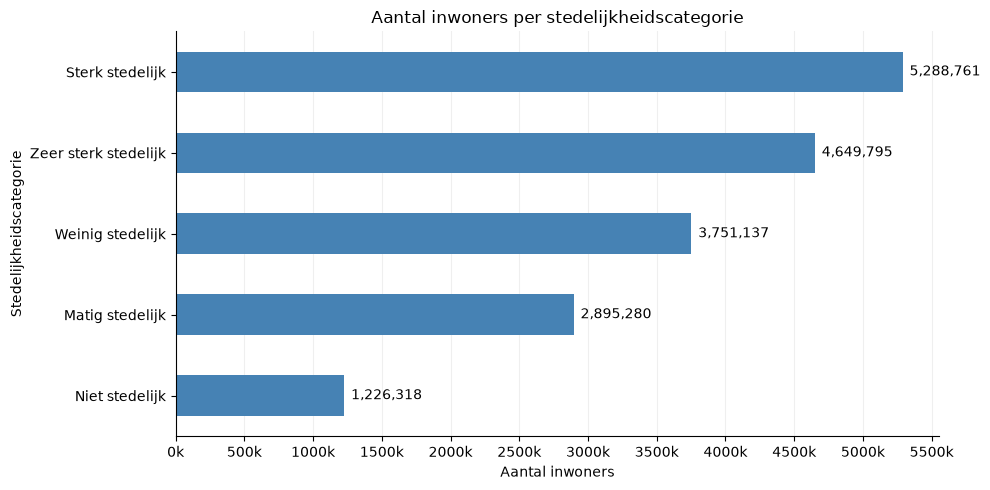

In [ ]:
gemeenten = df[df['SoortRegio_2'].str.strip() == 'Gemeente']

df_stedelijkheid = gemeenten.groupby('MateVanStedelijkheid_125')['AantalInwoners_5'].sum()

print(df_stedelijkheid)
#De vijf stedelijkheidscategorieën zijn:
#1. Zeer sterk stedelijk
#2. Sterk stedelijk
#3. Matig stedelijk
#4. Weinig stedelijk
#5. Niet stedelijk
df_stedelijkheid = gemeenten.groupby('MateVanStedelijkheid_125')['AantalInwoners_5'].sum()

df_stedelijkheid.index = df_stedelijkheid.index.map({
    1: 'Zeer sterk stedelijk',
    2: 'Sterk stedelijk',
    3: 'Matig stedelijk',
    4: 'Weinig stedelijk',
    5: 'Niet stedelijk'
})

print(df_stedelijkheid)

import matplotlib.ticker as ticker

ax = df_stedelijkheid.sort_values().plot(
    kind='barh',
    figsize=(10, 5),
    color='steelblue'
)

# Aantallen achter de staven
ax.bar_label(ax.containers[0], padding=5, fmt='{:,}')

# X-as in duizendtallen
ax.xaxis.set_major_locator(ticker.MultipleLocator(500000))
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{x/1000:.0f}k')
)

# Bovenste en rechter rand verwijderen
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Rustige rasterlijnen
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)

plt.title('Aantal inwoners per stedelijkheidscategorie')
plt.xlabel('Aantal inwoners')
plt.ylabel('Stedelijkheidscategorie')

plt.tight_layout()
plt.show()

#In de grafiek kan je zien dat het aantal inwoners per stedelijkheidscategorie heel erg kunnen verschillen. Tussen sterk stedelijk en zeer sterk stedelijk zit al een verschil van bijna 650k inwoners. 
#Dit zou bijvoorbeeld kunnen omdat in sterk stedelijke gebieden mensen dicht bij elkaar wonen, en in niet stedelijk juist veel verder uit elkaar. Hier moet weer rekening mee worden gehouden met de elektriciteit, omdat het in dichtbebouwde gebieden het lastiger kan zijn om ruimte te vinden voor bv de kabels. Ook kan er daardoor op 1 gebied veel elektriciteit nodig zijn.
#Om de elektriciteitsbehoefte te kunnen weten moet je dus rekening houden met meerdere factoren door elkaar heen.

## Sprint 5

## Sprint 6

### Eindadvies